# Лабораторная работа № 2. Классификация

**Цель:** прогноз выживания пассажиров Titanic и сравнение Decision Tree, Random Forest,
Gradient Boosting, SVM и KNN с константным baseline.

Целевая переменная — `Survived`: 1 — выжил, 0 — погиб.
Основная метрика — **F1 для класса 1**, минимальный порог — **F1 > 0.70**.
Дополнительно рассчитаны Accuracy, Precision, Recall и матрицы ошибок.

Источник данных: [Titanic Dataset, Yasser H — Kaggle](https://www.kaggle.com/datasets/yasserh/titanic-dataset).
Основание работы: `lab02.pdf`, `classification.ipynb`, `metrics.ipynb` и `preza.pdf` из материалов курса.

## 1. Данные и первичная проверка

Версии зависимостей зафиксированы в `requirements.txt`. Случайные процедуры используют `random_state=42`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, make_scorer,
)

RANDOM_STATE = 42
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11})
%matplotlib inline

print('pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__)

pandas: 2.3.3 | scikit-learn: 1.6.1


Использован предоставленный файл `Titanic-Dataset.xls`, фактически содержащий CSV.
Его копия без изменения байтов сохранена в `data/titanic.csv`.

In [2]:
DATA_PATH = Path('data/titanic.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('classification/data/titanic.csv')

data = pd.read_csv(DATA_PATH)
print('Размер данных:', data.shape)
display(data.head())

Размер данных: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Проверены типы столбцов, пропуски, повторяющиеся строки и уникальность идентификаторов.

In [3]:
overview = pd.DataFrame({
    'Тип': data.dtypes.astype(str),
    'Пропусков': data.isna().sum(),
    'Доля пропусков': data.isna().mean(),
    'Уникальных значений': data.nunique(),
})
display(overview.round(3))
print('Полных повторов:', data.duplicated().sum())
print('PassengerId уникален:', data['PassengerId'].is_unique)
display(data['Survived'].value_counts().sort_index().to_frame('Количество'))

assert data['PassengerId'].is_unique
assert data['Survived'].notna().all()
assert set(data['Survived'].unique()) == {0, 1}

,Тип,Пропусков,Доля пропусков,Уникальных значений
PassengerId,int64,0,0.000,891
Survived,int64,0,0.000,2
Pclass,int64,0,0.000,3
Name,object,0,0.000,891
Sex,object,0,0.000,2
Age,float64,177,0.199,88
SibSp,int64,0,0.000,7
Parch,int64,0,0.000,7
Ticket,object,0,0.000,681
Fare,float64,0,0.000,248


Полных повторов: 0
PassengerId уникален: True


,Количество
Survived,
0,549
1,342


Пропуски имеются в Age (177), Cabin (687) и Embarked (2).
Полных дубликатов нет, PassengerId уникален.
Целевой класс 1 представлен 342 пассажирами (38.4%), класс 0 — 549 (61.6%).
Дисбаланс умеренный: высокая Accuracy возможна при игнорировании выживших,
поэтому основным критерием служит F1 класса 1.

## 2. Выбор признаков и разбиение

Выбраны семь признаков: Age, SibSp, Parch, Fare, Pclass, Sex, Embarked.
Survived отделён от входов. PassengerId, Name и Ticket исключены как идентификаторы
или высококардинальные строки; Cabin исключён из-за 77.1% пропусков и большого числа категорий.
Новые признаки на основе имён, билетов и исходов родственников не создавались.

Разбиение 80/20 выполнено с `stratify=y` и `random_state=42`.

In [4]:
numeric_features = ['Age', 'SibSp', 'Parch', 'Fare']
categorical_features = ['Pclass', 'Sex', 'Embarked']
feature_columns = numeric_features + categorical_features
excluded_columns = {'Survived', 'PassengerId', 'Name', 'Ticket', 'Cabin'}

X = data[feature_columns].copy()
y = data['Survived'].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

split_summary = pd.DataFrame({
    'Количество': [len(X_train), len(X_test)],
    'Класс 0': [(y_train == 0).sum(), (y_test == 0).sum()],
    'Класс 1': [(y_train == 1).sum(), (y_test == 1).sum()],
    'Доля класса 1': [y_train.mean(), y_test.mean()],
}, index=['Train', 'Test'])
display(split_summary.round(4))

assert excluded_columns.isdisjoint(X.columns)
assert X_train.index.intersection(X_test.index).empty
train_data = X_train.copy()
train_data['Survived'] = y_train

,Количество,Класс 0,Класс 1,Доля класса 1
Train,712,439,273,0.3834
Test,179,110,69,0.3855


## 3. Исследование обучающей выборки

,count,mean,std,min,25%,50%,75%,max
Age,575.0,29.808,14.485,0.42,21.000,28.500,39.0,80.000
SibSp,712.0,0.493,1.061,0.00,0.000,0.000,1.0,8.000
Parch,712.0,0.390,0.838,0.00,0.000,0.000,0.0,6.000
Fare,712.0,31.820,48.059,0.00,7.896,14.454,31.0,512.329
Pclass,712.0,2.309,0.834,1.00,2.000,3.000,3.0,3.000


,Пропусков на train
Age,137
SibSp,0
Parch,0
Fare,0
Pclass,0
Sex,0
Embarked,2


,count,mean
Sex,,
female,253,0.743
male,459,0.185


,count,mean
Pclass,,
1,171,0.649
2,150,0.447
3,391,0.243


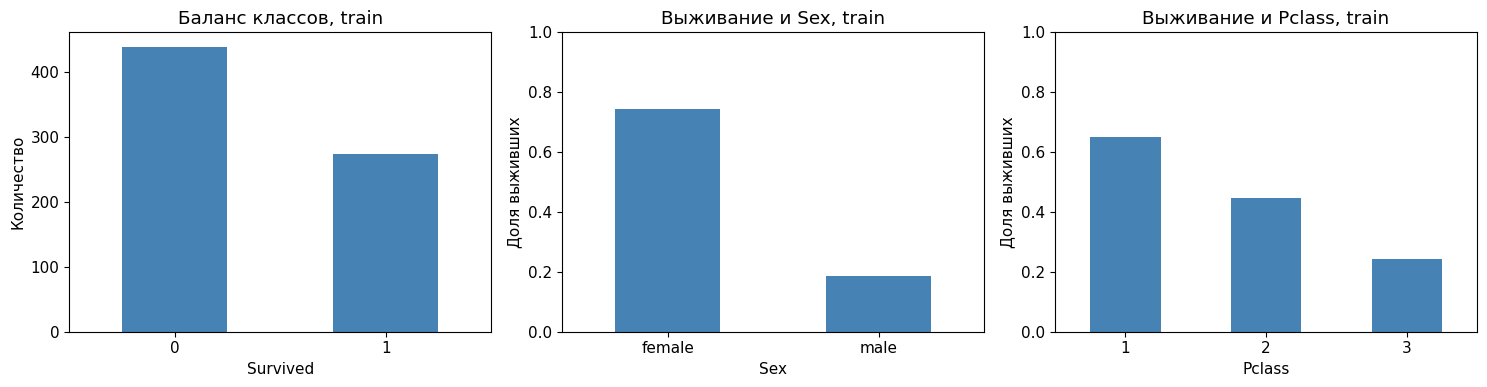

In [5]:
display(X_train.describe().T.round(3))
display(X_train.isna().sum().to_frame('Пропусков на train'))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
y_train.value_counts().sort_index().plot.bar(ax=axes[0], color='steelblue', rot=0)
axes[0].set(xlabel='Survived', ylabel='Количество', title='Баланс классов, train')
for ax, column in zip(axes[1:], ['Sex', 'Pclass']):
    summary = train_data.groupby(column)['Survived'].agg(['count', 'mean'])
    display(summary.round(3))
    summary['mean'].plot.bar(ax=ax, color='steelblue', rot=0)
    ax.set(xlabel=column, ylabel='Доля выживших', title=f'Выживание и {column}, train', ylim=(0, 1))
plt.tight_layout()
plt.show()

На train доля выживших среди женщин составляет 74.3%, среди мужчин — 18.5%.
Для классов билета 1, 2 и 3 доли равны 64.9%, 44.7% и 24.3%.
Sex и Pclass сохранены как информативные признаки. Групповые различия являются наблюдаемыми связями,
а не оценками причинного эффекта изменения пола или класса билета.

Распределения Age и Fare исследованы по известным значениям обучающей части.

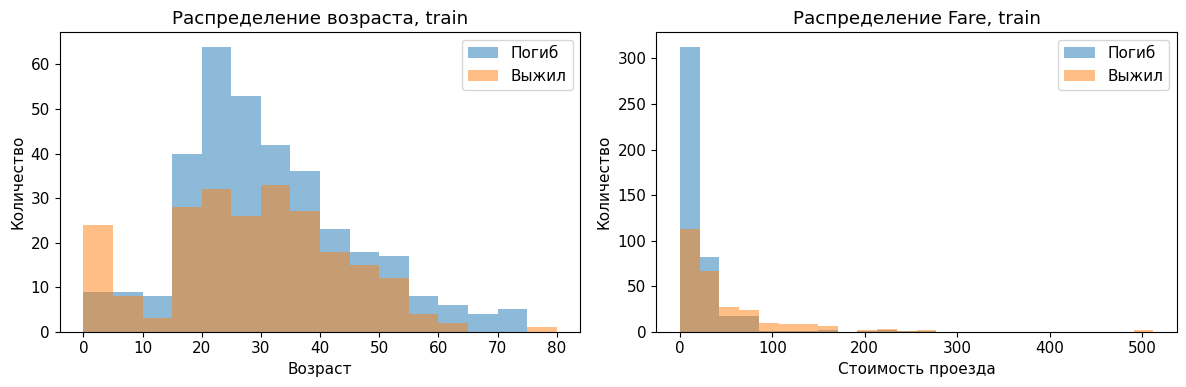

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for survived, label in [(0, 'Погиб'), (1, 'Выжил')]:
    part = train_data.loc[train_data['Survived'] == survived]
    axes[0].hist(part['Age'].dropna(), bins=np.arange(0, 85, 5), alpha=0.5, label=label)
    axes[1].hist(part['Fare'], bins=np.linspace(0, X_train['Fare'].max(), 25), alpha=0.5, label=label)
axes[0].set(xlabel='Возраст', ylabel='Количество', title='Распределение возраста, train')
axes[1].set(xlabel='Стоимость проезда', ylabel='Количество', title='Распределение Fare, train')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

Fare имеет правый хвост: большинство билетов существенно дешевле наиболее дорогих.
Возрастные распределения классов перекрываются; возраст отдельно не определяет исход.
Неизвестный возраст не приравнивается к нулю. Пассажиры с пропусками и редкими значениями сохранены.
На train отсутствует 137 значений Age и 2 значения Embarked.

## 4. Предобработка

Числовые пропуски заполняются медианой train, категориальные — наиболее частым значением train.
Pclass, Sex и Embarked кодируются One-Hot. Для SVM и KNN числовые признаки дополнительно стандартизуются:
их алгоритмы зависят от геометрии и расстояний. Для деревьев масштабирование не применяется.
Все обучаемые преобразования включены в Pipeline и заново обучаются внутри каждого CV-фолда.

In [7]:
def make_preprocessor(scale_numeric=False):
    numeric_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale_numeric:
        numeric_steps.append(('scaler', StandardScaler()))

    categorical_steps = [
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]
    return ColumnTransformer([
        ('num', Pipeline(numeric_steps), numeric_features),
        ('cat', Pipeline(categorical_steps), categorical_features),
    ])


def make_model(classifier, scale_numeric=False):
    return Pipeline([
        ('preprocess', make_preprocessor(scale_numeric)),
        ('classifier', classifier),
    ])

## 5. Метрики и baseline

Положительный класс — `Survived=1`. Использованы:

$$Accuracy=\frac{TP+TN}{N},\quad Precision=\frac{TP}{TP+FP},\quad Recall=\frac{TP}{TP+FN},$$
$$F_1=\frac{2PR}{P+R}=\frac{2TP}{2TP+FP+FN}.$$

FP — погибший пассажир, ошибочно предсказанный выжившим; FN — выживший, ошибочно предсказанный погибшим.
`zero_division=0` задаёт нулевую метрику при отсутствии положительных предсказаний.

In [8]:
def classification_metrics(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'Recall': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        'F1': f1_score(y_true, y_pred, pos_label=1, zero_division=0),
    }


scoring = {
    'Accuracy': 'accuracy',
    'Precision': make_scorer(precision_score, pos_label=1, zero_division=0),
    'Recall': make_scorer(recall_score, pos_label=1, zero_division=0),
    'F1': make_scorer(f1_score, pos_label=1, zero_division=0),
}

Baseline — `DummyClassifier(strategy='most_frequent')`, предсказывающий наиболее частый класс train.
Его тестовые метрики и матрица ошибок приведены вместе с остальными моделями после этапа выбора.

In [9]:
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
baseline_class = baseline.predict(X_train.iloc[:1])[0]
print('Постоянный прогноз baseline:', baseline_class)
display(pd.Series(classification_metrics(y_train, baseline.predict(X_train)), name='Train baseline'))

Постоянный прогноз baseline: 0


Accuracy     0.616573
Precision    0.000000
Recall       0.000000
F1           0.000000
Name: Train baseline, dtype: float64

## 6. Обязательные модели и проверенные настройки

Для каждого из пяти семейств проверены три конфигурации. Подбор ограничен обучающей частью;
порог классификации не оптимизировался по test, используются стандартные методы `predict`.

In [10]:
candidates = {
    'Baseline': DummyClassifier(strategy='most_frequent'),
    'DT_depth3': make_model(DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, random_state=RANDOM_STATE)),
    'DT_depth4': make_model(DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=RANDOM_STATE)),
    'DT_depth5': make_model(DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, random_state=RANDOM_STATE)),
    'RF_leaf2': make_model(RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1)),
    'RF_leaf4': make_model(RandomForestClassifier(n_estimators=300, min_samples_leaf=4, random_state=RANDOM_STATE, n_jobs=-1)),
    'RF_depth6': make_model(RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1)),
    'GB_depth2': make_model(GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=2, min_samples_leaf=5, random_state=RANDOM_STATE)),
    'GB_depth3': make_model(GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, min_samples_leaf=5, random_state=RANDOM_STATE)),
    'GB_default': make_model(GradientBoostingClassifier(random_state=RANDOM_STATE)),
    'SVM_C1': make_model(SVC(C=1, kernel='rbf', gamma='scale'), scale_numeric=True),
    'SVM_C3': make_model(SVC(C=3, kernel='rbf', gamma='scale'), scale_numeric=True),
    'SVM_C10': make_model(SVC(C=10, kernel='rbf', gamma='scale'), scale_numeric=True),
    'KNN_5': make_model(KNeighborsClassifier(n_neighbors=5), scale_numeric=True),
    'KNN_9': make_model(KNeighborsClassifier(n_neighbors=9), scale_numeric=True),
    'KNN_15': make_model(KNeighborsClassifier(n_neighbors=15), scale_numeric=True),
}

## 7. Кросс-валидация и выбор решения

Использована `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`.
Варианты сравниваются по среднему F1 класса 1 на общих проверочных фолдах.
В таблице также приведены остальные CV-метрики, разброс F1 и средняя обучающая F1.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in candidates.items():
    scores = cross_validate(
        model, X_train, y_train, cv=cv, scoring=scoring,
        return_train_score=True, n_jobs=1, error_score='raise',
    )
    row = {'Вариант': name}
    for metric in scoring:
        row[f'CV {metric}'] = scores[f'test_{metric}'].mean()
    row['CV std F1'] = scores['test_F1'].std()
    row['Train F1'] = scores['train_F1'].mean()
    cv_rows.append(row)

cv_table = pd.DataFrame(cv_rows).set_index('Вариант')
display(cv_table.round(4))

,CV Accuracy,CV Precision,CV Recall,CV F1,CV std F1,Train F1
Вариант,,,,,,
Baseline,0.6166,0.0000,0.0000,0.0000,0.0000,0.0000
DT_depth3,0.8048,0.8096,0.6484,0.7164,0.0296,0.7564
DT_depth4,0.8118,0.8300,0.6446,0.7230,0.0296,0.7597
DT_depth5,0.8090,0.8218,0.6447,0.7214,0.0129,0.7854
RF_leaf2,0.8160,0.7984,0.7034,0.7465,0.0381,0.8785
RF_leaf4,0.8146,0.8210,0.6628,0.7328,0.0385,0.8339
RF_depth6,0.8146,0.8211,0.6628,0.7325,0.0464,0.8194
GB_depth2,0.8118,0.7982,0.6922,0.7382,0.0266,0.8203
GB_depth3,0.8244,0.8077,0.7179,0.7588,0.0410,0.8660


Из каждого семейства выбрана конфигурация с максимальным средним CV F1.
Основная модель также определяется по CV до вычисления тестовых метрик.

Выбранные варианты: {'Baseline': 'Baseline', 'Decision Tree': 'DT_depth4', 'Random Forest': 'RF_leaf2', 'Gradient Boosting': 'GB_depth3', 'SVM': 'SVM_C3', 'KNN': 'KNN_15'}
Основная модель по CV: Gradient Boosting


,CV Accuracy,CV Precision,CV Recall,CV F1,CV std F1,Train F1
Baseline,0.6166,0.0000,0.0000,0.0000,0.0000,0.0000
Decision Tree,0.8118,0.8300,0.6446,0.7230,0.0296,0.7597
Random Forest,0.8160,0.7984,0.7034,0.7465,0.0381,0.8785
Gradient Boosting,0.8244,0.8077,0.7179,0.7588,0.0410,0.8660
SVM,0.8244,0.8415,0.6740,0.7466,0.0229,0.7882
KNN,0.8174,0.8182,0.6776,0.7401,0.0226,0.7626


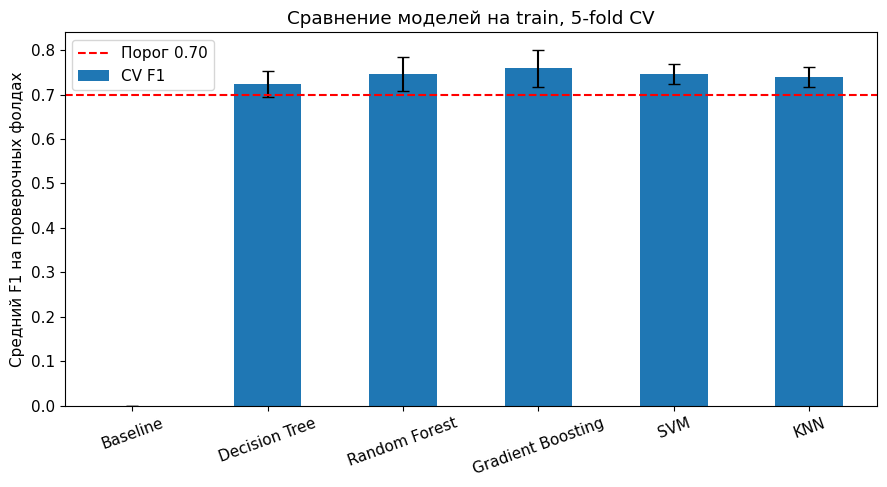

In [12]:
variant_groups = {
    'Baseline': ['Baseline'],
    'Decision Tree': ['DT_depth3', 'DT_depth4', 'DT_depth5'],
    'Random Forest': ['RF_leaf2', 'RF_leaf4', 'RF_depth6'],
    'Gradient Boosting': ['GB_depth2', 'GB_depth3', 'GB_default'],
    'SVM': ['SVM_C1', 'SVM_C3', 'SVM_C10'],
    'KNN': ['KNN_5', 'KNN_9', 'KNN_15'],
}
selected_variants = {
    family: cv_table.loc[variants, 'CV F1'].idxmax()
    for family, variants in variant_groups.items()
}
selection_table = cv_table.loc[list(selected_variants.values())].copy()
selection_table.index = list(selected_variants)
best_name = selection_table['CV F1'].idxmax()

print('Выбранные варианты:', selected_variants)
print('Основная модель по CV:', best_name)
display(selection_table.round(4))

selection_table['CV F1'].plot.bar(yerr=selection_table['CV std F1'], capsize=4, rot=20)
plt.axhline(0.70, color='red', linestyle='--', label='Порог 0.70')
plt.ylabel('Средний F1 на проверочных фолдах')
plt.title('Сравнение моделей на train, 5-fold CV')
plt.legend()
plt.tight_layout()
plt.show()

По CV выбрана основная модель Gradient Boosting (`GB_depth3`): средний F1 = 0.7588.
Выбранные конфигурации остальных семейств: DT_depth4, RF_leaf2, SVM_C3, KNN_15.
Средние CV F1 всех пяти моделей выше 0.70. Усложнение модели не давало монотонного улучшения;
у леса и бустинга заметен разрыв между обучающей и проверочной F1.
После этого этапа конфигурации, признаки и правило `predict` зафиксированы.

## 8. Итоговое обучение и тестовая оценка

По одному выбранному варианту каждого семейства обучено заново на всём train.
Все метрики рассчитаны на общей тестовой выборке из 179 пассажиров.

In [13]:
fitted_models = {}
test_predictions = {}
train_rows = []
test_rows = []
for family, variant in selected_variants.items():
    model = clone(candidates[variant])
    model.fit(X_train, y_train)
    train_prediction = model.predict(X_train)
    test_prediction = model.predict(X_test)
    fitted_models[family] = model
    test_predictions[family] = test_prediction
    train_rows.append({'Модель': family, **classification_metrics(y_train, train_prediction)})
    test_rows.append({'Модель': family, **classification_metrics(y_test, test_prediction)})

train_results = pd.DataFrame(train_rows).set_index('Модель')
results = pd.DataFrame(test_rows).set_index('Модель')
display(results.round(4))
display((results['F1'] > 0.70).to_frame('F1 > 0.70'))

final_model = fitted_models[best_name]
y_pred = test_predictions[best_name]
print('Основная модель, выбранная до теста:', best_name)
print(f"Test F1: {results.loc[best_name, 'F1']:.4f}")
assert results.loc[best_name, 'F1'] > 0.70, 'Локальный порог F1 > 0.70 не достигнут.'

,Accuracy,Precision,Recall,F1
Модель,,,,
Baseline,0.6145,0.0000,0.0000,0.0000
Decision Tree,0.7765,0.8085,0.5507,0.6552
Random Forest,0.8045,0.8148,0.6377,0.7154
Gradient Boosting,0.7989,0.7895,0.6522,0.7143
SVM,0.7989,0.8113,0.6232,0.7049
KNN,0.8101,0.8070,0.6667,0.7302


,F1 > 0.70
Модель,
Baseline,False
Decision Tree,False
Random Forest,True
Gradient Boosting,True
SVM,True
KNN,True


Основная модель, выбранная до теста: Gradient Boosting
Test F1: 0.7143


Все обученные модели превзошли Dummy baseline по четырём метрикам.
На локальном test F1 > 0.70 получен для Random Forest (0.7154), Gradient Boosting (0.7143),
SVM (0.7049) и KNN (0.7302). Decision Tree с F1 = 0.6552 порог не достиг.

По CV заранее выбран Gradient Boosting: на test Accuracy = 0.7989, Precision = 0.7895,
Recall = 0.6522, F1 = 0.7143. KNN имеет более высокий тестовый F1,
однако основная модель не перевыбиралась по test. Это различие с CV согласуется с вариативностью малой выборки.
Результат на скрытом тесте преподавателя заранее неизвестен.

При близкой Precision (около 0.79–0.81) различия F1 в основном связаны с Recall:
KNN находит 46 из 69 выживших (0.6667), дерево — 38 (0.5507).
Ограниченное дерево менее гибко описывает сочетания признаков; ансамбли и методы на расстояниях
на этом разбиении находят больше положительных объектов. Различия локальны и не устанавливают
универсального преимущества одного алгоритма.

### Матрицы ошибок всех моделей

Строки соответствуют истинному классу, столбцы — прогнозу. Порядок классов — [0, 1].

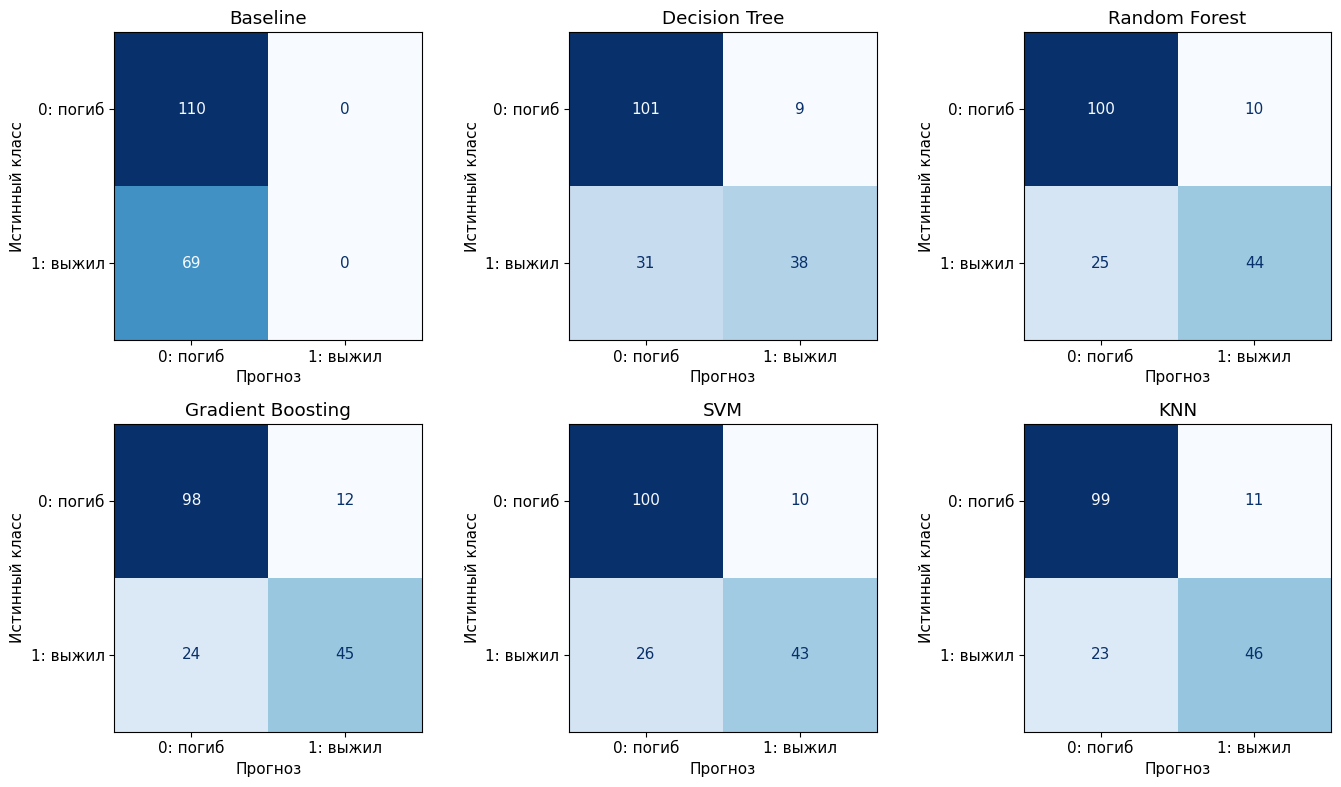

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, family in zip(axes.ravel(), selected_variants):
    matrix = confusion_matrix(y_test, test_predictions[family], labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=['0: погиб', '1: выжил']).plot(
        ax=ax, cmap='Blues', colorbar=False,
    )
    ax.set_title(family)
    ax.set_xlabel('Прогноз')
    ax.set_ylabel('Истинный класс')
plt.tight_layout()
plt.show()

### Обучение и обобщение

Сопоставлены train, CV и test. Для Decision Tree отдельно оценивается разрыв качества:
обучающая метрика не считается независимой проверкой.

In [15]:
generalization = pd.DataFrame({
    'Train Accuracy': train_results['Accuracy'],
    'Test Accuracy': results['Accuracy'],
    'Train F1': train_results['F1'],
    'CV F1': selection_table['CV F1'],
    'Test F1': results['F1'],
})
display(generalization.round(4))

,Train Accuracy,Test Accuracy,Train F1,CV F1,Test F1
Baseline,0.6166,0.6145,0.0000,0.0000,0.0000
Decision Tree,0.8357,0.7765,0.7484,0.7230,0.6552
Random Forest,0.9129,0.8045,0.8794,0.7465,0.7154
Gradient Boosting,0.8919,0.7989,0.8522,0.7588,0.7143
SVM,0.8525,0.7989,0.7835,0.7466,0.7049
KNN,0.8315,0.8101,0.7638,0.7401,0.7302


У выбранного Decision Tree Train Accuracy = 0.8357 против Test Accuracy = 0.7765;
Train F1 = 0.7484 против Test F1 = 0.6552 и CV F1 = 0.7230.
Несмотря на ограничения глубины и размера листа, сохраняются подгонка под обучение и нестабильность переноса.
Низкий Recall дерева (0.5507) указывает на пропуск значительной части выживших.

У леса Train F1 = 0.8794, у бустинга — 0.8522 при тестовых F1 около 0.715.
Их разрывы train–test также указывают на подгонку. Ансамбли при этом лучше дерева
улавливают сочетания характеристик и находят больше положительных объектов.
SVM и KNN используют другую геометрию решения; стандартизация необходима для сопоставимых расстояний.
Ни число деревьев, ни увеличение C или глубины не обеспечивают автоматического улучшения CV.

## 9. Важность признаков

Для Decision Tree, Random Forest и Gradient Boosting получены встроенные `feature_importances_`.
Вклады One-Hot-категорий суммированы по исходному признаку для сопоставления семейств.

,Decision Tree,Random Forest,Gradient Boosting
Sex,0.5935,0.3695,0.4783
Fare,0.0556,0.2125,0.1644
Age,0.1053,0.1832,0.1393
Pclass,0.2065,0.1254,0.1651
Embarked,0.0383,0.0390,0.0248
SibSp,0.0000,0.0376,0.0254
Parch,0.0008,0.0329,0.0027


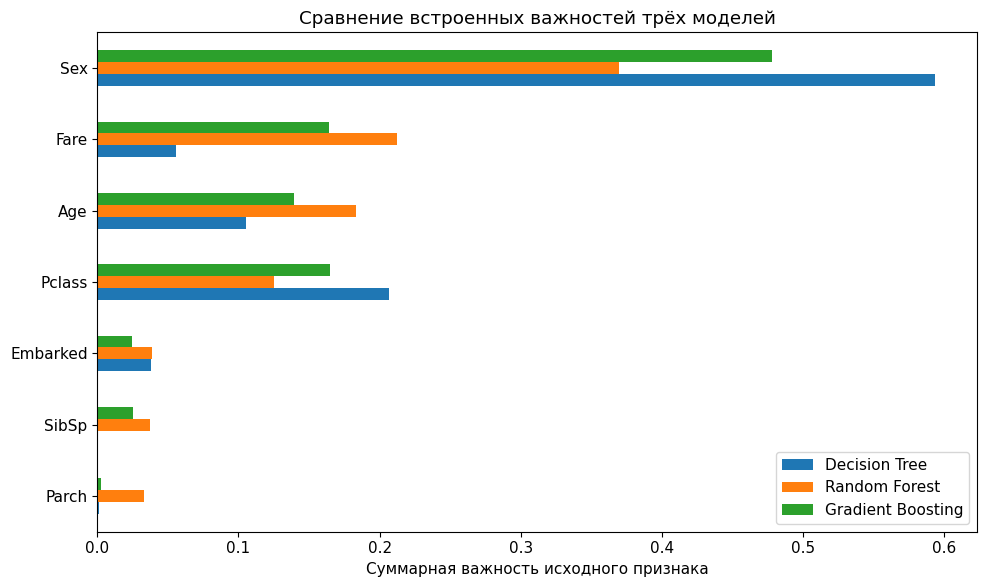

Decision Tree — топ-3: Sex, Pclass, Age
Random Forest — топ-3: Sex, Fare, Age
Gradient Boosting — топ-3: Sex, Pclass, Fare


In [16]:
encoded_importance = {}
for family in ['Decision Tree', 'Random Forest', 'Gradient Boosting']:
    pipeline = fitted_models[family]
    names = pipeline.named_steps['preprocess'].get_feature_names_out()
    values = pipeline.named_steps['classifier'].feature_importances_
    encoded_importance[family] = pd.Series(values, index=names)

encoded_importance = pd.DataFrame(encoded_importance)
raw_names = [name.split('__', 1)[1].split('_', 1)[0] for name in encoded_importance.index]
importances = encoded_importance.groupby(raw_names).sum()
order = importances['Random Forest'].sort_values().index
display(importances.loc[order[::-1]].round(4))

importances.loc[order].plot.barh(figsize=(10, 6))
plt.xlabel('Суммарная важность исходного признака')
plt.title('Сравнение встроенных важностей трёх моделей')
plt.tight_layout()
plt.show()

for family in importances:
    print(family, '— топ-3:', ', '.join(importances[family].nlargest(3).index))

| Модель | Три ведущих признака |
|---|---|
| Decision Tree | Sex, Pclass, Age |
| Random Forest | Sex, Fare, Age |
| Gradient Boosting | Sex, Pclass, Fare |

Все три модели сильнее всего используют Sex, что согласуется с различием долей выживших в EDA.
Его суммарная важность составляет 0.594 у дерева, 0.370 у леса и 0.478 у бустинга.
Pclass также заметен у дерева и бустинга; Fare может отражать связанную с классом билета информацию.
Лес распределяет вклад между большим числом числовых признаков, в частности Fare и Age.
Нулевой вклад SibSp в одном дереве не доказывает его бесполезность для других моделей.

Встроенные важности зависят от модели, корреляций и числа возможных разбиений.
Они не определяют направление связи и не доказывают причинность.
Наблюдаемая связь пола или класса с исходом не равна эффекту независимого изменения этого признака.

Первые два уровня выбранного дерева приведены для интерпретации правил.

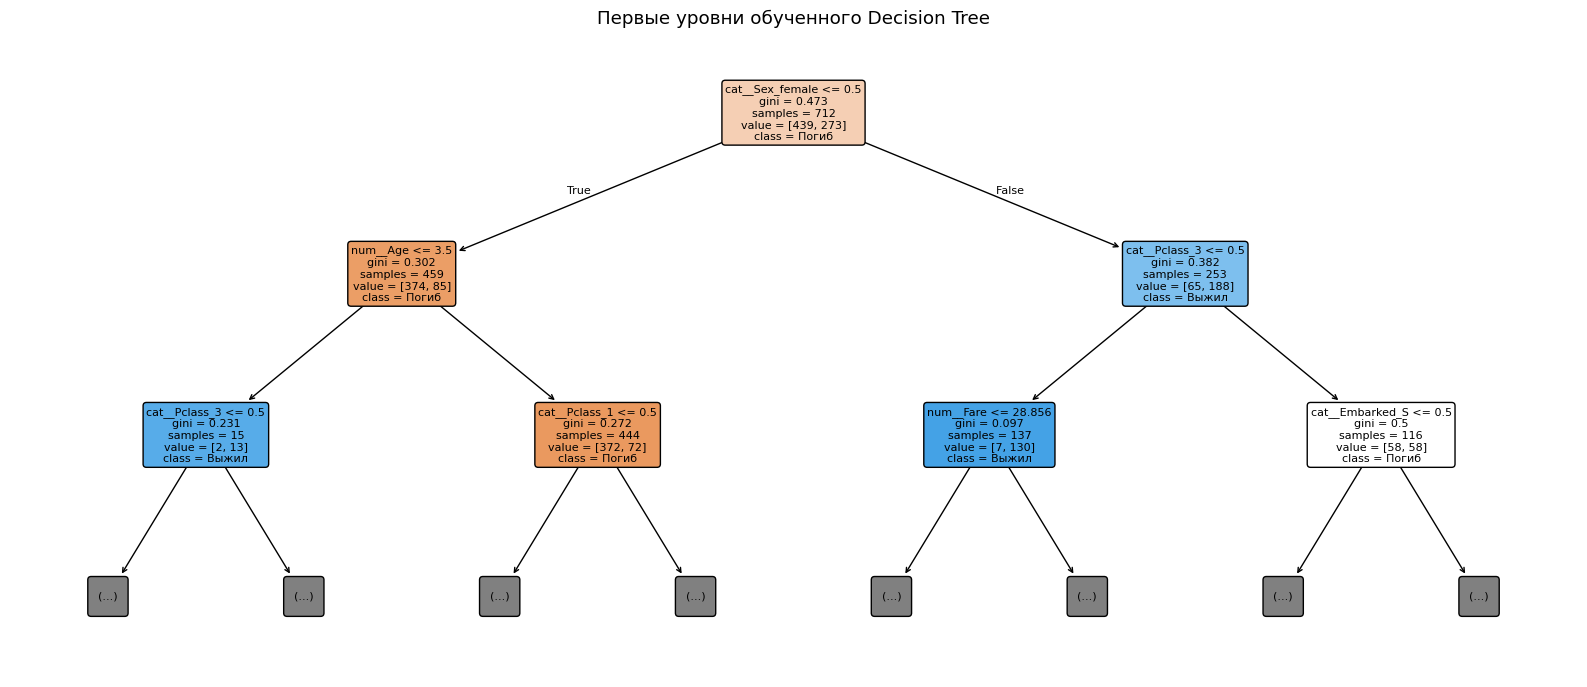

In [17]:
tree_pipeline = fitted_models['Decision Tree']
tree_names = tree_pipeline.named_steps['preprocess'].get_feature_names_out()
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(
    tree_pipeline.named_steps['classifier'],
    feature_names=tree_names, class_names=['Погиб', 'Выжил'],
    max_depth=2, filled=True, rounded=True, fontsize=8, ax=ax,
)
ax.set_title('Первые уровни обученного Decision Tree')
plt.tight_layout()
plt.show()

## 10. Анализ ошибок основной модели

Использованы ранее рассчитанные прогнозы модели, выбранной по CV.
Идентификатор PassengerId добавлен только для ссылки на ошибочные записи и не входит в X.

In [18]:
errors = X_test.copy()
errors.insert(0, 'PassengerId', data.loc[X_test.index, 'PassengerId'])
errors['y_true'] = y_test
errors['y_pred'] = y_pred
errors['wrong'] = errors['y_true'] != errors['y_pred']
errors['error_type'] = np.select(
    [(errors['y_true'] == 0) & (errors['y_pred'] == 1),
     (errors['y_true'] == 1) & (errors['y_pred'] == 0)],
    ['FP', 'FN'], default='Верно',
)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
print('Основная модель:', best_name)
print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp}')
print(f'Ошибок: {fp + fn} из {len(y_test)}')
print('Преобладающий тип ошибки:', 'FN' if fn > fp else 'FP' if fp > fn else 'поровну')

Основная модель: Gradient Boosting
TN=98, FP=12, FN=24, TP=45
Ошибок: 36 из 179
Преобладающий тип ошибки: FN


Ошибки исследованы отдельно по Sex, Pclass и фиксированным возрастным группам.
Пассажиры с неизвестным возрастом образуют отдельную группу.

,N,Выживших,Доля ошибок,F1,FP,FN
Группа,,,,,,
female,61,45,0.1967,0.8667,6,6
male,118,24,0.2034,0.3333,6,18


,N,Выживших,Доля ошибок,F1,FP,FN
Группа,,,,,,
1,45,25,0.2667,0.7600,6,6
2,34,20,0.1176,0.8947,1,3
3,100,24,0.2000,0.4737,5,15


,N,Выживших,Доля ошибок,F1,FP,FN
Группа,,,,,,
12–17,14,7,0.0000,1.0000,0,0
18–59,103,39,0.1845,0.7324,6,13
60+,8,4,0.2500,0.6667,0,2
До 12,14,7,0.3571,0.5455,1,4
Неизвестен,40,12,0.2500,0.5833,5,5


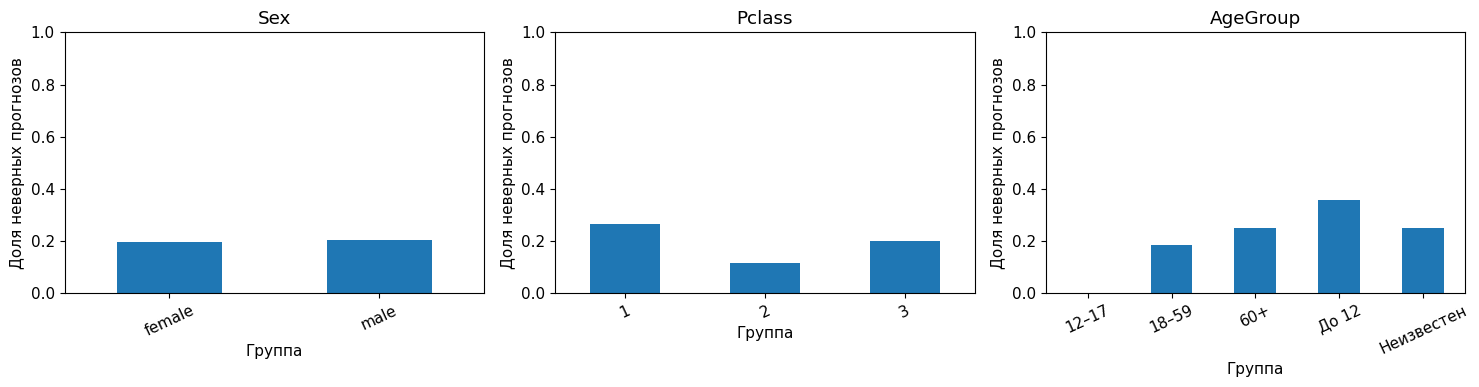

In [19]:
age_group = pd.cut(
    errors['Age'], bins=[0, 12, 18, 60, np.inf], right=False,
    labels=['До 12', '12–17', '18–59', '60+'],
)
errors['AgeGroup'] = age_group.astype('object').fillna('Неизвестен')


def group_error_metrics(frame, column):
    rows = []
    for group, part in frame.groupby(column, dropna=False):
        matrix = confusion_matrix(part['y_true'], part['y_pred'], labels=[0, 1])
        rows.append({
            'Группа': group,
            'N': len(part),
            'Выживших': int(part['y_true'].sum()),
            'Доля ошибок': part['wrong'].mean(),
            'F1': f1_score(part['y_true'], part['y_pred'], zero_division=0),
            'FP': int(matrix[0, 1]),
            'FN': int(matrix[1, 0]),
        })
    return pd.DataFrame(rows).set_index('Группа')


group_tables = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, ['Sex', 'Pclass', 'AgeGroup']):
    group_tables[column] = group_error_metrics(errors, column)
    display(group_tables[column].round(4))
    group_tables[column]['Доля ошибок'].plot.bar(ax=ax, rot=25)
    ax.set(title=column, ylabel='Доля неверных прогнозов', ylim=(0, 1))
plt.tight_layout()
plt.show()

У основной модели FN = 24 встречаются вдвое чаще FP = 12: она чаще пропускает выживших,
чем ошибочно относит погибших к выжившим.

По полу доли ошибок близки: 19.7% у женщин и 20.3% у мужчин.
При этом F1 различается существенно — 0.8667 и 0.3333:
среди мужчин пропущены 18 из 24 выживших, среди женщин — 6 из 45.
Одна общая доля ошибок скрывает это различие в полноте поиска класса 1.

В третьем классе билета пропущены 15 из 24 выживших; F1 = 0.4737.
Наибольшая возрастная доля ошибок наблюдается у детей до 12 лет — 5 из 14 (35.7%).
При неизвестном возрасте ошибочны 10 из 40 прогнозов (25%).
Идеальная метрика группы 12–17 лет относится лишь к 14 объектам и не гарантирует такого качества на новых данных.
Для малых групп выводы ограничены размером выборки.

Приведены по три примера FP и FN в порядке исходных строк.

In [20]:
mistakes = errors.loc[errors['wrong']].sort_values('PassengerId')
error_examples = pd.concat([
    mistakes.loc[mistakes['error_type'] == 'FP'].head(3),
    mistakes.loc[mistakes['error_type'] == 'FN'].head(3),
])
display(error_examples[
    ['PassengerId', 'Sex', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare',
     'Embarked', 'y_true', 'y_pred', 'error_type']
])

,PassengerId,Sex,Pclass,Age,SibSp,Parch,Fare,Embarked,y_true,y_pred,error_type
137,138,male,1,37.0,1,0,53.1,S,0,1,FP
199,200,female,2,24.0,0,0,13.0,S,0,1,FP
245,246,male,1,44.0,2,0,90.0,Q,0,1,FP
17,18,male,2,NaN,0,0,13.0,S,1,0,FN
23,24,male,1,28.0,0,0,35.5,S,1,0,FN
55,56,male,1,NaN,0,0,35.5,S,1,0,FN


| PassengerId | Тип | Наблюдение и возможное объяснение |
|---|---|---|
| 138 | FP | Мужчина, 37 лет, первый класс, Fare = 53.1. Принадлежность к группе с относительно высокой выживаемостью могла привести к переносу групповой закономерности на нетипичный индивидуальный исход. |
| 200 | FP | Женщина, 24 года, второй класс, фактически погибла. На train большинство женщин выжило; её исход отличается от частой для группы закономерности. |
| 18 | FN | Выживший мужчина второго класса с неизвестным возрастом. Возраст заменён обучающей медианой 28.5; недостаток индивидуальной информации и частое отсутствие выживания среди мужчин могут объяснять прогноз 0. |
| 24 | FN | Выживший мужчина 28 лет, первый класс. Доступные характеристики не обеспечили верный прогноз; сам класс билета не определяет исход однозначно. |

Эти объяснения являются гипотезами, а не доказанными причинами конкретного прогноза.
Положение пассажира во время эвакуации, доступность шлюпки и его действия не представлены в данных.
Ошибочные пассажиры сохранены в метриках; состав признаков и параметры после просмотра ошибок не менялись.

## 11. Проверка признаков и ограничений эксперимента

In [21]:
assert set(X.columns) == set(feature_columns)
assert excluded_columns.isdisjoint(X.columns)
assert data.loc[X_train.index, 'PassengerId'].isin(
    data.loc[X_test.index, 'PassengerId']
).sum() == 0

print('Входы модели:', list(X.columns))
print('Исключённые столбцы:', sorted(excluded_columns))
print('Совпадений выбранных характеристик у разных строк:', X.duplicated().sum())
print('Модель зафиксирована до оценки test:', best_name)
print('Финальная модель:', type(final_model.named_steps['classifier']).__name__)

Входы модели: ['Age', 'SibSp', 'Parch', 'Fare', 'Pclass', 'Sex', 'Embarked']
Исключённые столбцы: ['Cabin', 'Name', 'PassengerId', 'Survived', 'Ticket']
Совпадений выбранных характеристик у разных строк: 127
Модель зафиксирована до оценки test: Gradient Boosting
Финальная модель: GradientBoostingClassifier


## 12. Заключение

Выполнены анализ Titanic, предобработка без использования test, Dummy baseline,
сравнение пяти обязательных моделей и анализ матриц ошибок, важности и конкретных неверных прогнозов.

Gradient Boosting с 200 деревьями, `learning_rate=0.05`, глубиной 3 и минимальным листом 5
выбран по максимальному среднему CV F1 (0.7588).
На локальном test получены **Accuracy = 0.7989, Precision = 0.7895, Recall = 0.6522, F1 = 0.7143**.
Порог **F1 > 0.70 выполнен**. Лес, SVM и KNN также прошли локальный порог; дерево — нет.

Основное ограничение решения — пропуск выживших мужчин и отдельных редких групп.
Высокая важность Sex и Pclass согласуется с EDA, но не доказывает причинность.
Качество на единой скрытой выборке преподавателя остаётся неизвестным.